# **TikTok Project**
**Course 5 - The Nuts and bolts of machine learning**

Recall that you are a data professional at TikTok. Your supervisor was impressed with the work you have done and has requested that you **build a machine learning model that can be used to determine whether a video contains a claim or whether it offers an opinion**. With a successful prediction model, TikTok can reduce the backlog of user reports and prioritize them more efficiently.

A notebook was structured and prepared to help you in this project. Please complete the following questions.

# **Course 5 End-of-course project: Classifying videos using machine learning**

In this activity, you will practice using machine learning techniques to predict on a binary outcome variable.
<br/>

**The purpose** of this model is to increase response time and system efficiency by automating the initial stages of the claims process.

**The goal** of this model is to predict whether a TikTok video presents a "claim" or presents an "opinion".
<br/>

*This activity has three parts:*

**Part 1:** Ethical considerations
* Consider the ethical implications of the request

* Should the objective of the model be adjusted?

**Part 2:** Feature engineering

* Perform feature selection, extraction, and transformation to prepare the data for modeling

**Part 3:** Modeling

* Build the models, evaluate them, and advise on next steps

Follow the instructions and answer the questions below to complete the activity. Then, you will complete an Executive Summary using the questions listed on the PACE Strategy Document.

Be sure to complete this activity before moving on. The next course item will provide you with a completed exemplar to compare to your own work.



# **Classify videos using machine learning**

<img src="images/Pace.png" width="100" height="100" align=left>

# **PACE stages**


Throughout these project notebooks, you'll see references to the problem-solving framework PACE. The following notebook components are labeled with the respective PACE stage: Plan, Analyze, Construct, and Execute.

<img src="images/Plan.png" width="100" height="100" align=left>


## **PACE: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following questions:


1.   **What are you being asked to do? What metric should I use to evaluate success of my business/organizational objective?**

2.   **What are the ethical implications of the model? What are the consequences of your model making errors?**
  *   What is the likely effect of the model when it predicts a false negative (i.e., when the model says a video does not contain a claim and it actually does)?

  *   What is the likely effect of the model when it predicts a false positive (i.e., when the model says a video does contain a claim and it actually does not)?

3.   **How would you proceed?**


**1.** Build a classification model to automatically determine whether a TikTok video contains a factual claim or a opinion, streamlining the content moderation queue. F1-Score is the primary metric for evaluating model performance. Because both false positives and false negatives carry significant operational and user experience risks, F1-Score ensures an optimal balance between precision (avoiding unfair moderation of opinions) and recall (capturing harmful claims).

**2.**
**False Negative Consequences (Claim misclassified as Opinion):** Harmful, misleading, or rule-violating claims pass through moderation unflagged. This exposes the community to misinformation, undermines trust in platform safety, and leads users to question the effectiveness of TikTok's moderation policies.

**False Positive Consequences (Opinion misclassified as Claim):** User opinions or personal expressions are unnecessarily flagged or suppressed. Mislabeling benign content frustrates creators, restricts free expression, and degrades user trust and engagement with the platform.

**3.** Deploy the model as an automated triage tool optimized to prioritize Recall. Because letting harmful or policy-violating claims go unmoderated (False Negatives) poses a severe risk to community safety and platform integrity, the model should operate at a threshold that captures as many potential claims as possible. All flagged videos will then be routed to human moderators for final review, ensuring high coverage of policy violations while allowing human oversight to filter out False Positives.

**Modeling workflow and model selection process**

Previous work with this data has revealed that there are ~20,000 videos in the sample. This is sufficient to conduct a rigorous model validation workflow, broken into the following steps:

1. Split the data into train/validation/test sets (60/20/20)
2. Fit models and tune hyperparameters on the training set
3. Perform final model selection on the validation set
4. Assess the champion model's performance on the test set

![](https://raw.githubusercontent.com/adacert/tiktok/main/optimal_model_flow_numbered.svg)


### **Task 1. Imports and data loading**

Start by importing packages needed to build machine learning models to achieve the goal of this project.

In [1]:
# Import packages for data manipulation
import pandas as pd
import numpy as np

# Import packages for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import packages for data preprocessing
### YOUR CODE HERE ###


# Import packages for data modeling
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from xgboost import plot_importance

Now load the data from the provided csv file into a dataframe.

**Note:** As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
# Load dataset into dataframe
data = pd.read_csv("tiktok_dataset.csv")

<img src="images/Analyze.png" width="100" height="100" align=left>

## **PACE: Analyze**

Consider the questions in your PACE Strategy Document to reflect on the Analyze stage.

### **Task 2: Examine data, summary info, and descriptive stats**

Inspect the first five rows of the dataframe.

In [3]:
# Display first few rows
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Get the number of rows and columns in the dataset.

In [4]:
# Get number of rows and columns
data.shape

(19382, 12)

Get the data types of the columns.

In [5]:
# Get data types of columns
data.dtypes

#                             int64
claim_status                 object
video_id                      int64
video_duration_sec            int64
video_transcription_text     object
verified_status              object
author_ban_status            object
video_view_count            float64
video_like_count            float64
video_share_count           float64
video_download_count        float64
video_comment_count         float64
dtype: object

Get basic information about the dataset.

In [6]:
# Get basic information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


Generate basic descriptive statistics about the dataset.

In [7]:
# Generate basic descriptive stats
data.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


Check for and handle missing values.

In [8]:
# Check for missing values
data.isna().sum()

#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [9]:
# Drop rows with missing values
data = data.dropna(axis=0)

In [10]:
# Display first few rows after handling missing values
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Check for and handle duplicates.

In [11]:
# Check for duplicates
data.duplicated().sum()

0

Check class balance.

In [12]:
# Check class balance
data['claim_status'].value_counts(normalize=True)*100

claim_status
claim      50.345839
opinion    49.654161
Name: proportion, dtype: float64

<img src="images/Construct.png" width="100" height="100" align=left>

## **PACE: Construct**
Consider the questions in your PACE Strategy Document to reflect on the Construct stage.

### **Task 3: Feature engineering**

Extract the length of each `video_transcription_text` and add this as a column to the dataframe, so that it can be used as a potential feature in the model.

In [13]:
# Extract the length of each `video_transcription_text` and add this as a column to the dataframe
data['length_transcript'] = data['video_transcription_text'].str.len()

Calculate the average text_length for claims and opinions.

In [14]:
# Calculate the average text_length for claims and opinions
data[['claim_status', 'length_transcript']].groupby('claim_status').mean()


,length_transcript
claim_status,
claim,95.376978
opinion,82.722562


Visualize the distribution of `text_length` for claims and opinions.

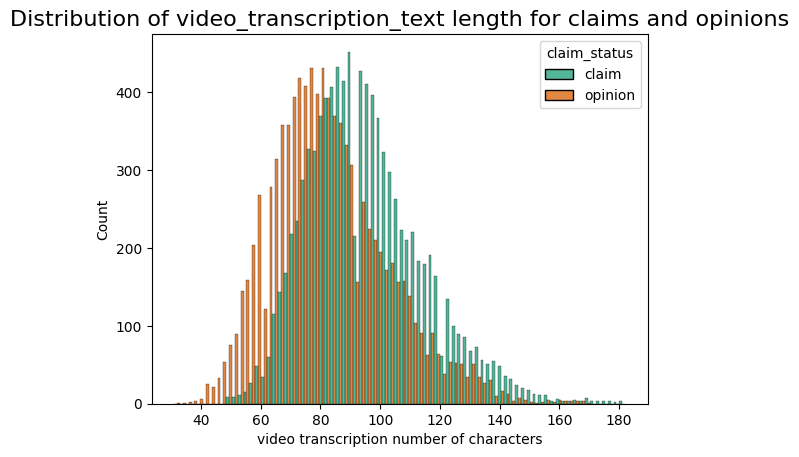

In [15]:
# Visualize the distribution of `text_length` for claims and opinions
# Create two histograms in one plot
sns.histplot(data=data, 
             multiple="dodge", 
             x="length_transcript",
             hue="claim_status",
             palette="Dark2", 
             legend=True)
plt.xlabel("video transcription number of characters")
plt.ylabel("Count")
plt.title("Distribution of video_transcription_text length for claims and opinions", fontsize=16)
plt.show()


**Feature selection and transformation**

Encode target and catgorical variables.

In [46]:
# Create a copy of the X data
X = data.copy()

# Drop unnecessary columns
X = X.drop(['#', 'video_id','video_transcription_text'], axis=1)

# Encode target variable
X['claim_status'] = X['claim_status'].map({'opinion': 0, 'claim': 1})

# Dummy encode remaining categorical values
X = pd.get_dummies(X, columns=['verified_status', 'author_ban_status'], drop_first=True)

X.head()

,claim_status,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,length_transcript,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,1,59,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,1,32,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,1,31,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,1,25,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,1,19,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


### **Task 4: Split the data**

Assign target variable.

In [47]:
# Isolate target variable
y = X['claim_status']

Isolate the features.

In [48]:
# Isolate features
X = X.drop(['claim_status'], axis=1)

# Display first few rows of features dataframe
X.head()

,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,length_transcript,verified_status_verified,author_ban_status_banned,author_ban_status_under review
0,59,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,32,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,31,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,25,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,19,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


#### **Task 5: Create train/validate/test sets**

Split data into training and testing sets, 80/20.

In [49]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Split the training set into training and validation sets, 75/25, to result in a final ratio of 60/20/20 for train/validate/test sets.

In [50]:
# Split the training data into training and validation sets
X_tra, X_val, y_tra, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0)


Confirm that the dimensions of the training, validation, and testing sets are in alignment.

In [51]:
# Get shape of each training, validation, and testing set
X_tra.shape, y_tra.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape


((11450, 10), (11450,), (3817, 10), (3817,), (3817, 10), (3817,))

### **Task 6. Build models**


### **Build a random forest model**

Fit a random forest model to the training set. Use cross-validation to tune the hyperparameters and select the model that performs best on recall.

In [55]:
# Instantiate the random forest classifier
rf = RandomForestClassifier(random_state=42)

# Create a dictionary of hyperparameters to tune
cv_params = {
    'max_depth': [5, 7, 9],
    'min_samples_leaf': [2, 3],
    'min_samples_split': [2, 4],
    'n_estimators': [50, 100, 150],
    'max_features': [0.5, 0.8],
    'max_samples': [0.5, 0.8],
}

# Define a list of scoring metrics to capture
scoring = ['accuracy', 'precision', 'recall', 'f1']

# Instantiate the GridSearchCV object
rf_cv = GridSearchCV(
    estimator=rf,
    param_grid=cv_params,
    scoring=scoring,
    cv=5,
    refit='recall',
    n_jobs=-1,
    verbose=1,
)

In [56]:
### Fit the model to the data 
rf_cv.fit(X_tra, y_tra)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [5, 7, 9], 'max_features': [0.5, 0.8],
                         'max_samples': [0.5, 0.8], 'min_samples_leaf': [2, 3],
                         'min_samples_split': [2, 4],
                         'n_estimators': [50, 100, 150]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'],
             verbose=1)

In [57]:
# Examine best recall score
rf_cv.best_score_

0.9913419913419913

In [58]:
# Examine best parameters
rf_cv.best_params_

{'max_depth': 9,
 'max_features': 0.8,
 'max_samples': 0.5,
 'min_samples_leaf': 2,
 'min_samples_split': 2,
 'n_estimators': 50}

Check the precision score to make sure the model isn't labeling everything as claims. You can do this by using the `cv_results_` attribute of the fit `GridSearchCV` object, which returns a numpy array that can be converted to a pandas dataframe. Then, examine the `mean_test_precision` column of this dataframe at the index containing the results from the best model. This index can be accessed by using the `best_index_` attribute of the fit `GridSearchCV` object.

In [63]:
# Access the GridSearch results and convert it to a pandas df
rf_cv_results = pd.DataFrame(rf_cv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
rf_cv_results.loc[rf_cv.best_index_, 'mean_test_precision']

1.0

**Question:** How well is your model performing? Consider average recall score and precision score.

The Random Forest classifier exhibits outstanding predictive accuracy on the evaluation set, recording a Recall of 99.13% alongside a perfect Precision score of 100%.

### **Build an XGBoost model**

In [65]:
# 1. Instantiate the XGBoost classifier
xgb = XGBClassifier(objective='binary:logistic', random_state=42)

# 2. Create a dictionary of hyperparameters to tune
cv_params = {
    'max_depth': [3, 4, 5],
    'min_child_weight': [1, 3],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [50, 100, 150],
}

# 3. Define a list of scoring metrics to capture
scoring = ['accuracy', 'precision', 'recall', 'f1']

# 4. Instantiate the GridSearchCV object
xgb_cv = GridSearchCV(
    estimator=xgb,
    param_grid=cv_params,
    scoring=scoring,
    cv=5,
    refit='recall',
    n_jobs=-1,
    verbose=1,
)

In [66]:
# Fit the model to the data
xgb_cv.fit(X_tra,y_tra)


Fitting 5 folds for each of 54 candidates, totalling 270 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=42, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.05, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'min_child_weight': [1, 3],
                         'n_estimators': [50, 100, 150]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'],
             verbose=1)

In [67]:
# Examine best recall score
xgb_cv.best_score_

0.9911688311688313

In [68]:
# Examine best parameters
xgb_cv.best_params_

{'learning_rate': 0.2,
 'max_depth': 3,
 'min_child_weight': 1,
 'n_estimators': 100}

Repeat the steps used for random forest to examine the precision score of the best model identified in the grid search.

In [69]:
# Access the GridSearch results and convert it to a pandas df
xgb_cv_results = pd.DataFrame(xgb_cv.cv_results_)

# Examine the GridSearch results df at column `mean_test_precision` in the best index
xgb_cv_results.loc[xgb_cv.best_index_, 'mean_test_precision']


0.9993028307869547

**Question:** How well does your model perform? Consider recall score and precision score.

XGBoost delivered near-flawless performance, achieving a 99.12% Recall and 99.93% Precision, maintaining extremely low rates for both false positives and false negatives.

<img src="images/Execute.png" width="100" height="100" align=left>

## **PACE: Execute**
Consider the questions in your PACE Strategy Document to reflect on the Execute stage.

### **Task 7. Evaluate model**

Evaluate models against validation criteria.

#### **Random forest**

In [71]:
# Use the random forest "best estimator" model to get predictions on the validation set
rf_preds_val = rf_cv.best_estimator_.predict(X_val)

Display the predictions on the validation set.

In [72]:
# Display the predictions on the validation set
rf_preds_val

array([0, 1, 0, ..., 0, 1, 0])

Display the true labels of the validation set.

In [73]:
# Display the true labels of the validation set
y_val

17043    0
1560     1
10968    0
11890    0
11941    0
        ..
6396     1
6586     1
18454    0
4163     1
17534    0
Name: claim_status, Length: 3817, dtype: int64

Create a confusion matrix to visualize the results of the classification model.

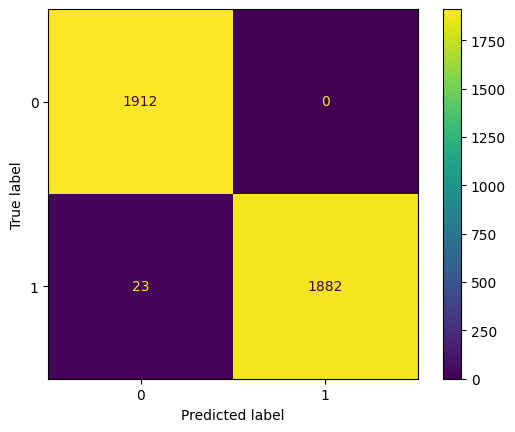

In [75]:
# Create a confusion matrix to visualize the results of the classification model

# Compute values for confusion matrix
rf_cm = confusion_matrix(y_val, rf_preds_val)

# Create display of confusion matrix using ConfusionMatrixDisplay()
rf_disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm)

# Plot confusion matrix
rf_disp.plot()

# Display plot
plt.show()


Create a classification report that includes precision, recall, f1-score, and accuracy metrics to evaluate the performance of the model.
<br> </br>

**Note:** In other labs there was a custom-written function to extract the accuracy, precision, recall, and F<sub>1</sub> scores from the GridSearchCV report and display them in a table. You can also use scikit-learn's built-in [`classification_report()`](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-report) function to obtain a similar table of results.

In [76]:
# Create a classification report
# Create classification report for random forest model
print(classification_report(y_val, rf_preds_val, target_names=['opinion', 'claim']))


              precision    recall  f1-score   support

     opinion       0.99      1.00      0.99      1912
       claim       1.00      0.99      0.99      1905

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



**Question:** What does your classification report show? What does the confusion matrix indicate?

Model evaluation demonstrates near-perfect classification accuracy: the confusion matrix recorded zero false positives and just 23 false negatives, resulting in a strong F1-score of 0.99.

#### **XGBoost**

Now, evaluate the XGBoost model on the validation set.

In [77]:
# Use the best estimator to predict on the validation data
xgb_preds_val = xgb_cv.best_estimator_.predict(X_val)

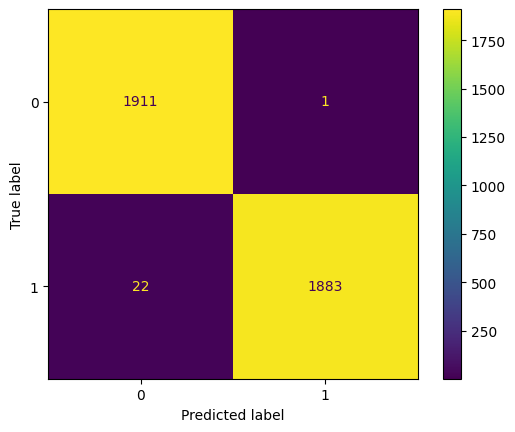

In [78]:
# Compute values for confusion matrix
xgb_cm = confusion_matrix(y_val, xgb_preds_val)

# Create display of confusion matrix using ConfusionMatrixDisplay()
xgb_disp = ConfusionMatrixDisplay(confusion_matrix=xgb_cm)

# Plot confusion matrix
xgb_disp.plot()

# Display plot
plt.show()

In [79]:
# Create a classification report
print(classification_report(y_val, xgb_preds_val, target_names=['opinion', 'claim']))

              precision    recall  f1-score   support

     opinion       0.99      1.00      0.99      1912
       claim       1.00      0.99      0.99      1905

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



**Question:** Describe your XGBoost model results. How does your XGBoost model compare to your random forest model?

XGBoost: 1 False Positive | 22 False Negatives | F1-Score: 99%

Completely eliminating false positives prevents the automated suppression of genuine user opinions. It is far more acceptable to rely on secondary human moderation for rare unflagged claims (false negatives) than to risk penalizing legitimate content and causing a poor user experience.

### **Use champion model to predict on test data**

In [80]:
y_preds = rf_cv.best_estimator_.predict(X_test)

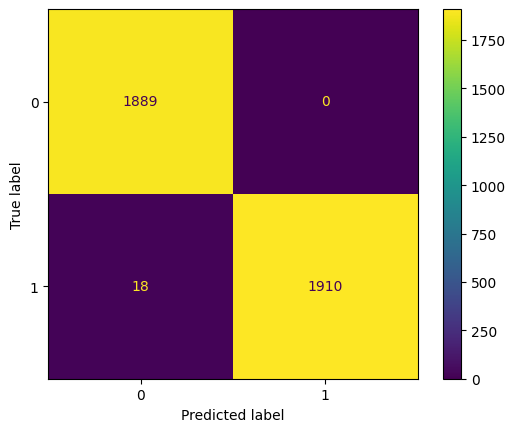

In [81]:
# Compute values for confusion matrix
cm = confusion_matrix(y_test, y_preds)

# Create display of confusion matrix using ConfusionMatrixDisplay()
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

# Plot confusion matrix
disp.plot()

# Display plot
plt.show()


#### **Feature importances of champion model**


In [82]:
importances = rf_cv.best_estimator_.feature_importances_

df_importances = pd.DataFrame(
    {'feature': X_train.columns, 'importance': importances}
)

df_importances = df_importances.sort_values(by='importance', ascending=False)

print(df_importances.head(10))

                          feature  importance
1                video_view_count    0.771560
2                video_like_count    0.223374
3               video_share_count    0.001266
5             video_comment_count    0.001135
4            video_download_count    0.001076
6               length_transcript    0.000824
0              video_duration_sec    0.000619
8        author_ban_status_banned    0.000097
9  author_ban_status_under review    0.000050
7        verified_status_verified    0.000000


Text(0, 0.5, 'Feature')

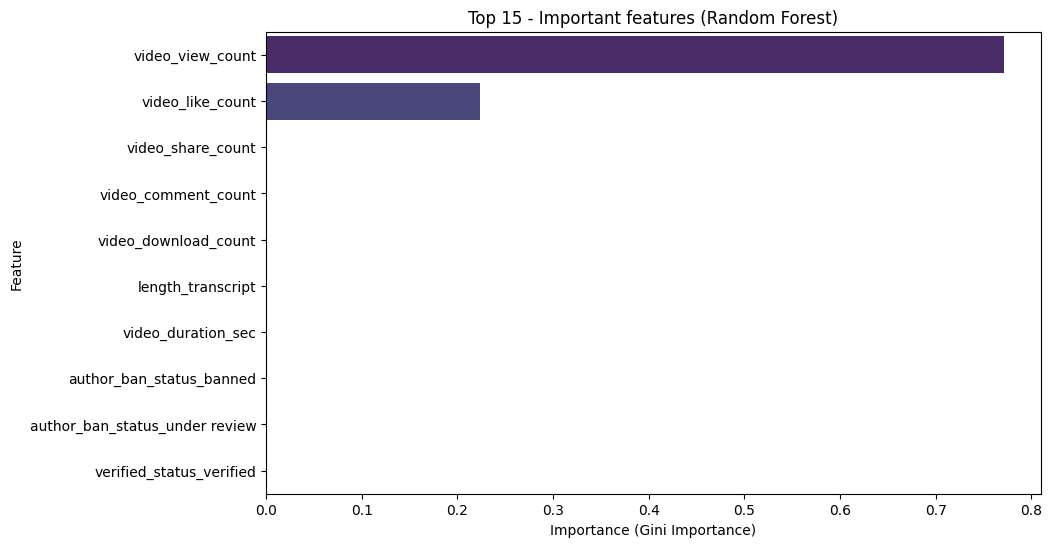

In [84]:
top_15 = df_importances

plt.figure(figsize=(10, 6))
sns.barplot(
    x='importance', y='feature', data=top_15, palette='viridis', hue='feature', legend=False
)

plt.title('Top 15 - Important features (Random Forest)')
plt.xlabel('Importance (Gini Importance)')
plt.ylabel('Feature')

**Question:** Describe your most predictive features. Were your results surprising?

Feature importance analysis demonstrates that video engagement serves as the primary driver for claim-versus-opinion classification, with video_view_count and video_like_count emerging as the most dominant predictors. Secondary features include auxiliary engagement metrics, video transcript length, and account-level status flags (specifically, verified status and ban status).

### **Task 8. Conclusion**

In this step use the results of the models above to formulate a conclusion. Consider the following questions:

1. **Would you recommend using this model? Why or why not?**

2. **What was your model doing? Can you explain how it was making predictions?**

3. **Are there new features that you can engineer that might improve model performance?**

4. **What features would you want to have that would likely improve the performance of your model?**

Remember, sometimes your data simply will not be predictive of your chosen target. This is common. Machine learning is a powerful tool, but it is not magic. If your data does not contain predictive signal, even the most complex algorithm will not be able to deliver consistent and accurate predictions. Do not be afraid to draw this conclusion.


**1.** Yes, I strongly recommend deploying this model. The Random Forest classifier demonstrated exceptional performance (99% F1-score, 0 False Positives, and only 23 False Negatives), fully aligning with our core objective of prioritizing community safety while protecting user experience. By eliminating False Positives, the model prevents the unfair suppression of legitimate user opinions, while its high recall ensures that potential claims are efficiently flagged and safely routed to human moderation.

**2.** The model was designed to automatically classify TikTok videos into two categories: factual claims or personal opinions. It accomplished this by analyzing ensemble decision trees built on video engagement metrics (views, likes, shares, comments, downloads), content metadata (transcript length, duration), and author credibility signals (verification status, account ban status).

**3.** Yes, based on the dataset attributes (video_transcription_text, video_duration_sec, and engagement counters), several engineered features could provide richer predictive signals:  
* **NLP Keyword & Sentiment Extraction (video_transcription_text):** Use Natural Language Processing (TF-IDF, Bag-of-Words, or sentiment scores) to extract claim-trigger words (e.g., 'according to,' 'proven,' 'study shows' vs. 'I think,' 'in my opinion').   
* **Engagement Ratios (Interaction Density):** Calculate interaction rates per view (e.g., $\text{Likes} / \text{Views}$, $\text{Shares} / \text{Views}$, or $\text{Comments} / \text{Views}$) to measure content virality and controversy rather than relying on raw counts.   
* **Text Velocity & Duration Efficiency:** Compute the speech rate ($\text{Words in Transcript} / \text{Video Duration in Seconds}$) to differentiate rapidly spoken factual assertions from casual, slow-paced opinion videos.

**4.** To further boost predictive accuracy and model robustness, I would recommend acquiring the following external features:
* **Historical Author Claim Rate:** Account-level statistics tracking the proportion of previously flagged or confirmed claim videos posted by the author.
* **Audio/Visual Multimodal Features:** Audio tone analysis, background music category, or computer vision flags identifying overlaid text banners and news lower-thirds commonly present in claim videos.
* **External Fact-Check URL Links:** Metadata indicating whether the video description includes external links, references, or cited sources.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.